In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
def stacked_bar(data, row_labels=None, col_labels=None, title="", ax=None):
    data = np.asarray(data)
    nrows, ncols = data.shape

    if row_labels is None:
        row_labels = [str(i) for i in range(nrows)]
    if col_labels is None:
        col_labels = [str(j) for j in range(ncols)]

    if ax is None:
        fig, ax = plt.subplots()
    else:
        fig = ax.get_figure()

    x = np.arange(nrows)
    width = 0.08

    for j in range(ncols):
        height = data[:, j]
        shift = 0.1*j - 0.3
        ax.bar(x+shift, height, width=width, label=col_labels[j])

    ax.set_xticks(x, row_labels, rotation=40, ha='right', rotation_mode='anchor')
    ax.set_title(title)
    ax.legend()

    return fig, ax

In [5]:
# Rejection rates
rejection = np.loadtxt("rejection.npy.txt")
rejection = np.take(rejection, [0,1,2,3,4,5,6,8], axis=0) # Remove pure [[4,2,2]]

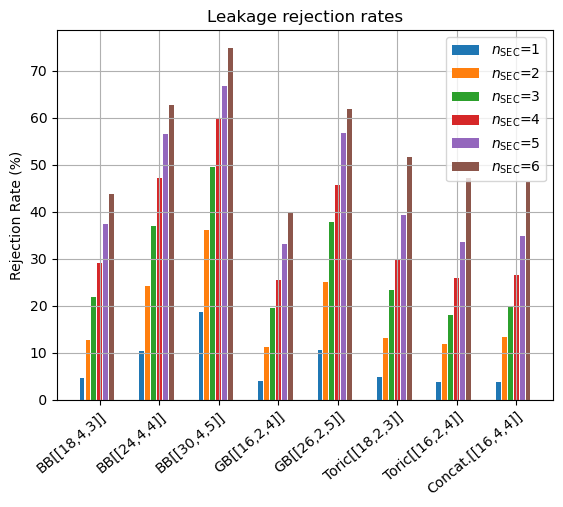

In [6]:
lbls = ['BB[[18,4,3]]', 'BB[[24,4,4]]', 'BB[[30,4,5]]', 'GB[[16,2,4]]', 'GB[[26,2,5]]', 'Toric[[18,2,3]]', 'Toric[[16,2,4]]', 'Concat.[[16,4,4]]']
bars = [r"$n_{\text{SEC}}$="+f"{i}" for i in range(1,7)]
fig, ax = stacked_bar(rejection, row_labels=lbls, col_labels=bars)
ax.set_ylabel("Rejection Rate (%)")
ax.set_title("Leakage rejection rates")
ax.set_yticks(np.arange(0,0.8,0.1), [f"{100*i:2.0f}" for i in np.arange(0,0.8,0.1)])
ax.grid()
# plt.savefig("/Users/tham/Desktop/trim/rejection_in.pdf", bbox_inches='tight')